# Phase 4: Churn Prediction (Baseline Models)

In Phase 2 I created features for each customer and a Churn label (1 = the customer did not buy in the next 90 days).

In this notebook I want to predict which customers will churn. This is supervised learning, because I already know the answer (Churn) for every customer, so the model can learn from it.

What I do in this notebook:
- Split the data into training and test parts
- Start with a dummy model as the minimum score
- Train simple models: Logistic Regression and Decision Tree
- Compare them using accuracy, precision, recall, F1 and ROC-AUC
- Choose which baseline model works better and explain why

In Phase 5 I will try stronger models (ensembles) and compare them with these baselines.

# Importing the Required Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)

# Loading the data

In [2]:
churn = pd.read_parquet("../data/processed/churn_train.parquet")
print(churn.shape)

(5256, 14)


# Separating X and Y variables

In [3]:
X = churn.drop(columns=['Customer ID', 'Churn'])

In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 5256 entries, 0 to 5255
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Frequency             5256 non-null   int64  
 1   Monetary              5256 non-null   float64
 2   AvgOrderValue         5256 non-null   float64
 3   AvgBasketSize         5256 non-null   float64
 4   Recency               5256 non-null   int64  
 5   Tenure                5256 non-null   int64  
 6   AvgDaysBetweenOrders  5256 non-null   float64
 7   IsOneTimeBuyer        5256 non-null   int64  
 8   Orders_Last90         5256 non-null   int64  
 9   UniqueProducts        5256 non-null   int64  
 10  Q4_Share              5256 non-null   float64
 11  IsUK                  5256 non-null   int64  
dtypes: float64(5), int64(7)
memory usage: 492.9 KB


In [5]:
y = churn['Churn']

In [6]:
y.info()

<class 'pandas.Series'>
RangeIndex: 5256 entries, 0 to 5255
Series name: Churn
Non-Null Count  Dtype
--------------  -----
5256 non-null   int64
dtypes: int64(1)
memory usage: 41.2 KB


In [7]:
print(X.shape)
print(y.shape)

(5256, 12)
(5256,)


# Splitting into training and test data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [9]:
print(X_train.shape, X_test.shape)

(4204, 12) (1052, 12)


In [10]:
print(y_train.mean() , y_test.mean())

0.5647002854424358 0.564638783269962


### Insights:
- I split the data into 80% training (4,204 customers) and 20% test (1,052 customers).
- I used stratify, so both parts have the same churn rate (56.5%). This makes the test fair.

## Dummy baseline
- This model always predicts the most common answer (churn) for every customer. It doesn't learn anything.
- I use it as the minimum score. My real models must do better than this.

In [11]:
dummy = DummyClassifier(strategy='most_frequent') # 'most_frequent' means “always predict the most common class,” which here is 1 (churn).

In [12]:
dummy.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.44,0.56]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](12,)","['Frequency','Monetary','AvgOrderValue',...,'UniqueProducts','Q4_Share', 'IsUK']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,12
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [13]:
y_pred = dummy.predict(X_test)
y_prob = dummy.predict_proba(X_test)[:, 1]

In [14]:
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision: ", round(precision_score(y_test, y_pred), 3))
print("Recall: ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob), 3))


Accuracy:  0.565
Precision:  0.565
Recall:  1.0
F1 Score:  0.722
ROC-AUC:  0.5


## What and Why we are using these metrics now:
- Accuracy: out of all customers, how many did the model get right?
- Precision: of the customers it said would churn, how many really churned?
- Recall: of the customers who really churned, how many did it catch?
- F1: a balance of precision and recall in one number.
- ROC-AUC: how well the model ranks churners above non-churners. 0.5 is pure guessing; 1.0 is perfect.

### Insights:
- The dummy model predicts churn for everyone and still gets 0.565 accuracy and 0.722 F1.
- Its recall is 1.0 only because it says everyone will churn, so it catches every churner but is wrong about all the others.
- Its ROC-AUC is 0.5, which means it is no better than guessing.
- So accuracy and F1 alone can be misleading. I will use ROC-AUC as my main score, and my real models must beat these numbers.

## Logistic Regression
- This is my first real model. It gives each customer a churn probability.
- My features are skewed and on different ranges, so I use log and scaling first.
- I put log, scaling and the model together in a pipeline, so the same steps are always used in the same order.

In [15]:
log_reg = Pipeline([
    ('log', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000)),
])

In [16]:
log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Frequency','Monetary','AvgOrderValue',...,'UniqueProducts','Q4_Share', 'IsUK']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<ufunc 'log1p'>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [17]:
y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]

In [18]:
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision: ", round(precision_score(y_test, y_pred), 3))
print("Recall: ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC: ", round(roc_auc_score(y_test, y_prob), 3))

Accuracy:  0.735
Precision:  0.75
Recall:  0.795
F1 Score:  0.772
ROC-AUC:  0.789


### Insights:
- Logistic Regression has ROC-AUC 0.789, much better than the dummy (0.5), so it really learned to tell churners from non-churners.
- Accuracy went up from 0.565 to 0.735, and F1 went up from 0.722 to 0.772.
- Recall dropped from 1.0 to 0.795, because the model no longer predicts churn for everyone. It still catches about 80% of the customers who churned.
- Precision went up from 0.565 to 0.75, so when it says a customer will churn, it is right 3 out of 4 times.

## Function to evaluate models
- Instead of copying the same metric code for every model, I write a function that does it once.
- It gives back all the scores for a model as one row, so I can put all models in one table and compare them.
- It also gives the ROC-AUC on the training data, so I can check if a model is overfitting.

In [19]:
def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    train_prob = model.predict_proba(X_train)[:, 1]

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC_AUC': roc_auc_score(y_test, y_prob),
        'Train_ROC_AUC': roc_auc_score(y_train, train_prob),
    }

In [20]:
results = []
results.append(evaluate('Dummy', dummy))
results.append(evaluate('Logistic Regression', log_reg))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC
0,Dummy,0.565,0.565,1.000,0.722,0.500,0.500
1,Logistic Regression,0.735,0.750,0.795,0.772,0.789,0.804


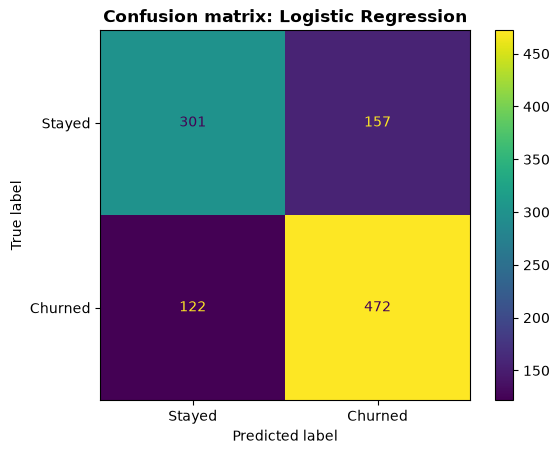

In [21]:
ConfusionMatrixDisplay.from_estimator(log_reg, X_test, y_test,
                                      display_labels=['Stayed', 'Churned'])
plt.title('Confusion matrix: Logistic Regression', fontweight='bold')
plt.show()

### Insights:
- My function gives the same scores as before, so it works correctly. Now I can compare all models in one table.
- Logistic Regression has train ROC-AUC 0.804 and test ROC-AUC 0.789. They are very close, so the model is not overfitting.
- In the confusion matrix, the model caught 472 churners but missed 122. It also gave 157 false alarms (customers it said would churn but who stayed).
- It correctly found 301 customers who stayed.

## Decision Tree
- A Decision Tree learns yes/no questions about the features to decide if a customer will churn.
- Trees don't need log or scaling, because they only check if a value is above or below a number.
- If a tree has no limit, it can memorise the training data (overfitting), so I compare a tree with no limit and a tree with a depth limit.

## Tree with no limit.

In [22]:
dec_tree = DecisionTreeClassifier(random_state=42)

In [23]:
dec_tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [24]:
results.append(evaluate('Decision Tree (no limit)', dec_tree))

## Tree with a depth limit

In [25]:
dec_tree_limit = DecisionTreeClassifier(max_depth=5, random_state=42)

In [26]:
dec_tree_limit.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [27]:
results.append(evaluate('Decision Tree (depth 5)', dec_tree_limit))

In [28]:
pd.DataFrame(results).round(3) # showing table of comparing metric scores between models

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC
0,Dummy,0.565,0.565,1.000,0.722,0.500,0.500
1,Logistic Regression,0.735,0.750,0.795,0.772,0.789,0.804
2,Decision Tree (no limit),0.647,0.687,0.690,0.688,0.641,1.000
3,Decision Tree (depth 5),0.718,0.735,0.781,0.758,0.769,0.828


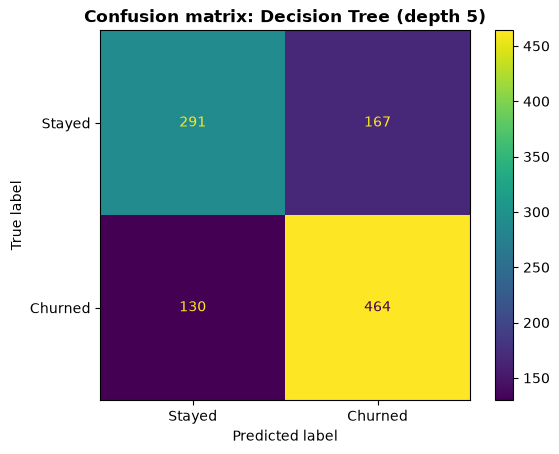

In [29]:
ConfusionMatrixDisplay.from_estimator(dec_tree_limit, X_test, y_test,
                                      display_labels=['Stayed', 'Churned'])
plt.title('Confusion matrix: Decision Tree (depth 5)', fontweight='bold')
plt.show()

### Insights:
- The tree with no limit has train ROC-AUC 1.0 but test ROC-AUC only 0.641. It memorised the training customers, so it is overfitting badly. It is even worse than Logistic Regression on every metric.
- With max_depth = 5, the train (0.828) and test (0.769) scores are much closer, and the test score went up from 0.641 to 0.769. Limiting the tree helped a lot.
- Logistic Regression is still the best so far. It has the highest ROC-AUC (0.789), and it is also better on accuracy, precision, recall and F1.
- Logistic Regression also has the smallest gap between train and test (0.804 vs 0.789), so it is the most stable model.
- In the confusion matrix, the depth-5 tree missed 130 churners and gave 167 false alarms. Logistic Regression missed only 122 churners and gave 157 false alarms, so it makes fewer mistakes of both kinds.

## Cross-validation
- One test set can be lucky or unlucky for a model, so I also use 5-fold cross-validation on the training data.
- The training data is split into 5 parts. The model is trained on 4 parts and tested on the 5th, 5 times.
- I look at the average score (how good) and the standard deviation (how stable).

In [30]:
cv_lr = cross_val_score(log_reg, X_train, y_train, cv=5, scoring='roc_auc')
cv_tree = cross_val_score(dec_tree_limit, X_train, y_train, cv=5, scoring='roc_auc')

In [31]:
print("Logistic Regression:", cv_lr.round(3))
print("Average:", round(cv_lr.mean(), 3), " Std:", round(cv_lr.std(), 3))

print("Decision Tree (depth 5):", cv_tree.round(3))
print("Average:", round(cv_tree.mean(), 3), " Std:", round(cv_tree.std(), 3))

Logistic Regression: [0.82  0.792 0.797 0.805 0.789]
Average: 0.801  Std: 0.011
Decision Tree (depth 5): [0.801 0.785 0.776 0.784 0.79 ]
Average: 0.787  Std: 0.008


### Insights:
- Logistic Regression has an average cross-validation ROC-AUC of 0.801 (± 0.011), close to its test score of 0.789, so the test result was reliable.
- The depth-5 tree has an average of 0.787 (± 0.008). This is higher than its test score (0.769), so the test set was a little unlucky for the tree, but it is still lower than Logistic Regression.
- The tree's scores are slightly more stable (std 0.008 vs 0.011), but the difference is very small. Logistic Regression is better on average.

## Comparing all models
- I put all models in one table with all the metrics, and add the cross-validation scores.
- I also draw ROC curves to see which model separates churners from non-churners best.

In [32]:
results_df = pd.DataFrame(results) # displaying the final table and storing it in a variable

### Adding the cross-validation averages as a new column.

In [33]:
cv_means = {'Logistic Regression': cv_lr.mean(), 'Decision Tree (depth 5)': cv_tree.mean()}

In [34]:
results_df['CV_ROC_AUC'] = results_df['Model'].map(cv_means)

In [35]:
results_df.sort_values('ROC_AUC', ascending=False).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Train_ROC_AUC,CV_ROC_AUC
1,Logistic Regression,0.735,0.750,0.795,0.772,0.789,0.804,0.801
3,Decision Tree (depth 5),0.718,0.735,0.781,0.758,0.769,0.828,0.787
2,Decision Tree (no limit),0.647,0.687,0.690,0.688,0.641,1.000,NaN
0,Dummy,0.565,0.565,1.000,0.722,0.500,0.500,NaN


# Drawing ROC curves for all models in one chart

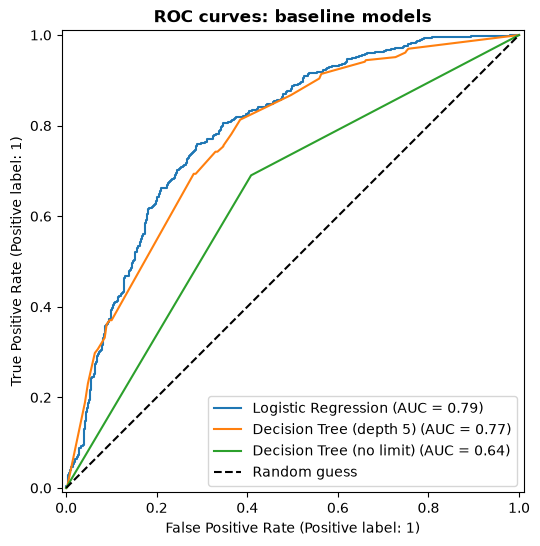

In [36]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=ax, name='Logistic Regression')
RocCurveDisplay.from_estimator(dec_tree_limit, X_test, y_test, ax=ax, name='Decision Tree (depth 5)')
RocCurveDisplay.from_estimator(dec_tree, X_test, y_test, ax=ax, name='Decision Tree (no limit)')

ax.plot([0, 1], [0, 1], 'k--', label='Random guess')

ax.set_title('ROC curves: baseline models', fontweight='bold')
ax.legend()
plt.show()

### Insights:
- The Logistic Regression curve is the highest and closest to the top-left corner, so it separates churners and non-churners best.
- The tree with no limit is the lowest curve and closest to the dashed line, because it overfitted.

## Model selection
- Logistic Regression has the highest test ROC-AUC (0.789) and the highest cross-validation ROC-AUC (0.801), so it is best at telling churners and non-churners apart.
- Among the real models, it is also the best on accuracy (0.735), precision (0.75), recall (0.795) and F1 (0.772).
- Recall matters most for the business, because missing a customer who will churn costs more than sending an offer to someone who would stay. Logistic Regression catches about 80% of churners and missed only 122, compared with 130 for the tree.
- Its train and test ROC-AUC are very close (0.804 vs 0.789), so it is not overfitting.
- It is also the simplest model and easy to explain.
- The tree with no limit was clearly overfitting (train 1.0, test 0.641), so I would not use it.
- So Logistic Regression is my best baseline model. In Phase 5 I will try ensemble models to see if they can beat it.

In [37]:
os.makedirs("../models", exist_ok=True)
results_df.to_csv("../models/baseline_results.csv", index=False) # Saving the results of baseline_models in csv for app to use

In [38]:
joblib.dump(log_reg, "../models/log_reg_baseline.pkl")

['../models/log_reg_baseline.pkl']

## Summary
- I trained a dummy model, Logistic Regression and two Decision Trees to predict churn.
- The dummy model got 0.565 accuracy but ROC-AUC 0.5, so I used ROC-AUC as my main score.
- Logistic Regression was the best baseline: test ROC-AUC 0.789, cross-validation 0.801, and it catches about 80% of churners.
- The tree with no limit overfitted badly (train 1.0, test 0.641). Limiting the depth to 5 fixed most of it (test 0.769).
- I saved the results table and the Logistic Regression model.
- Next, in Phase 5, I will try ensemble models (Random Forest, XGBoost and Stacking) and compare them with these baselines.